In [147]:
# 1. Cleaning Data:
    # Check missing values and duplicates
    # Remove duplicates
    # Convert numeric columns
    # Fix invalid ranges
    # Fill missing values
    # Clean categorical values
    # Fill pass_status using final_score

In [148]:
import pandas as pd

df=pd.read_csv('data/student_performance_raw.csv')

df.drop_duplicates('student_id',inplace=True)


C:\Users\saura\AppData\Local\Temp\ipykernel_19600\3923125680.py:5: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates('student_id',inplace=True)


In [149]:


df['final_score_numeric']=pd.to_numeric(df['final_score'],errors='coerce')

df['final_score_string']=df['final_score'].where(df['final_score_numeric'].isna())

df['final_score_string'].value_counts()

df.drop(columns=['final_score_numeric','final_score_string'],inplace=True)

df['final_score']=pd.to_numeric(df['final_score'],errors='coerce')

df.loc[df['final_score'].isna(),'final_score']=df['final_score'].median()


C:\Users\saura\AppData\Local\Temp\ipykernel_19600\2240538714.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['final_score_numeric','final_score_string'],inplace=True)


In [150]:

df['attendance_numeric']=pd.to_numeric(df['attendance'],errors='coerce')

df['attendance_string']=df['attendance'].where(df['attendance_numeric'].isna())

df['attendance_string'].value_counts()

df.drop(columns=['attendance_numeric','attendance_string'],inplace=True)

df['attendance']=df['attendance'].map({
    'ninety':'90',
    'absent':'Unknown'
}).fillna(df['attendance'])

df['attendance']=pd.to_numeric(df['attendance'],errors='coerce')


C:\Users\saura\AppData\Local\Temp\ipykernel_19600\1758726000.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['attendance_numeric','attendance_string'],inplace=True)


In [151]:
df['gender']=df['gender'].str.strip().str.lower()

df['gender']=df['gender'].map({
    'female':'Female',
    'male':'Male',
    'other':'Other',
    'm':'Male',
    'unknown':'Unknown'
})
df['gender']=df['gender'].fillna('Unknown')
df['gender'].value_counts()

gender
Female     465
Male       455
Other       40
Unknown     10
Name: count, dtype: int64

In [152]:

df['study_hours_numeric']=pd.to_numeric(df['study_hours'],errors='coerce')

df['study_hours_string']=df['study_hours'].where(df['study_hours_numeric'].isna())

df['study_hours_string'].value_counts()

df.drop(columns=['study_hours_string','study_hours_numeric'],inplace=True)

df['study_hours']=df['study_hours'].map({
    'five':'5',
    'many':'Unknown'
}).fillna(df['study_hours'])

df['study_hours']=pd.to_numeric(df['study_hours'],errors='coerce')
df.info()







<class 'pandas.DataFrame'>
RangeIndex: 970 entries, 0 to 969
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Unnamed: 0       970 non-null    int64  
 1   student_id       970 non-null    str    
 2   gender           970 non-null    str    
 3   study_hours      961 non-null    float64
 4   attendance       959 non-null    float64
 5   previous_score   960 non-null    str    
 6   sleep_hours      965 non-null    str    
 7   internet_access  965 non-null    str    
 8   final_score      970 non-null    float64
 9   pass_status      968 non-null    str    
dtypes: float64(3), int64(1), str(6)
memory usage: 75.9 KB


C:\Users\saura\AppData\Local\Temp\ipykernel_19600\425295155.py:7: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['study_hours_string','study_hours_numeric'],inplace=True)


In [153]:
df.loc[(df['study_hours']<0) | (df['study_hours']>12),'study_hours']=None
df.loc[(df['attendance']<0) | (df['attendance']>100),'study_hours']=None
df.loc[(df['final_score']<0) | (df['final_score']>100),'study_hours']=None



In [154]:
columns=['study_hours','attendance','final_score']

for col in columns:
    df[col]=df[col].fillna(df[col].median())


In [155]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

X=df[['study_hours','attendance']]
Y=df['final_score']

X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2)

model=LinearRegression()
model.fit(X_train,Y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](2,)","[4.54,0.14]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](2,)","['study_hours','attendance']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,37.78
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,2
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(2)


In [156]:
y_pred=model.predict(X_test)


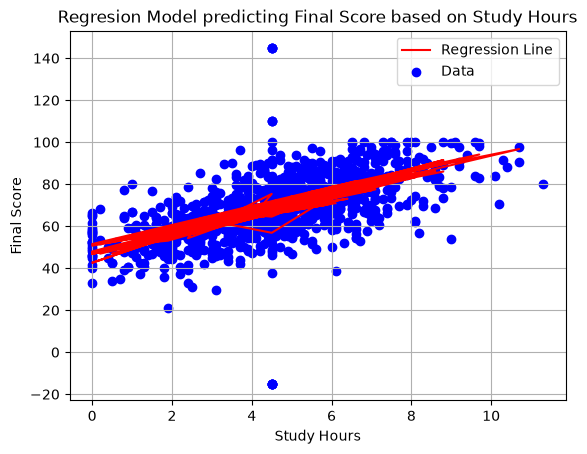

In [157]:
import matplotlib.pyplot as plt

plt.plot(X_test['study_hours'],y_pred,label='Regression Line',color='Red')
plt.scatter(X['study_hours'],Y,label='Data',color="Blue")
plt.xlabel("Study Hours")
plt.ylabel("Final Score")
plt.title("Regresion Model predicting Final Score based on Study Hours")
plt.grid(True)
plt.legend()

In [158]:
from sklearn.metrics import mean_squared_error,r2_score

r2=r2_score(y_pred,Y_test)
r2

-1.0608285229265388

In [159]:
new_value=pd.DataFrame({"study_hours":[10],"attendance":[78]})

new_prediction=model.predict(new_value)

print(f"New Value: {new_value}\n Predicted Value:{new_prediction}")
df['pass_status'].value_counts()

New Value:    study_hours  attendance
0           10          78
 Predicted Value:[93.92263]


pass_status
Pass       706
Fail       252
FAIL         2
Passed       2
Unknown      2
No           2
pass         2
Name: count, dtype: int64

In [160]:

df['pass_status']=df['pass_status'].map({
    'FAIL':'Fail',
    'Passed':'Pass',
    'Unknown':None,
    'No':'Fail',
    'pass':'Pass'
}).fillna(df['pass_status'])

def get_pass_fail(final_score):
    if final_score>=40:
        return 'Pass'
    else:
        return 'Fail'


# df.loc[df['pass_status'].isna(),'pass_status']=df['final_score'].apply(lambda x: 'Pass' if x>=40 else 'Fail')
df.loc[df['pass_status'].isna(),'pass_status']=df['final_score'].apply(get_pass_fail)


df['pass_status']=df['pass_status'].apply(lambda x: '1' if x=='Pass' else '0' )

df['pass_status']=pd.to_numeric(df['pass_status'],errors='coerce')

df['pass_status'].value_counts()

pass_status
1    712
0    258
Name: count, dtype: int64

In [161]:
from sklearn.linear_model import LogisticRegression

x_train,x_test,y_train,y_test=train_test_split(df[['study_hours','attendance']],df['pass_status'],test_size=0.2)

logistic_model=LogisticRegression()

logistic_model.fit(x_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [ ]:
value=pd.DataFrame({"study_hours":[10],"attendance":[78]})

predicted=logistic_model.predict(value)

print(value,"\n\n")
print(predicted)


   study_hours  attendance
0           10          78
[1]
